In [187]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [188]:
insurance=pd.read_csv('/content/Indian_Insurance_Data.csv')

In [189]:
insurance.head(1)

,age,weight,height,income_lpa,smoker,city,occupation,insurance_premium_category
0,50,57,176,29.9,False,Agra,Factory Worker,Medium


In [190]:
print("Shape:", insurance.shape)

Shape: (4000, 8)


In [191]:
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         4000 non-null   int64  
 1   weight                      4000 non-null   int64  
 2   height                      4000 non-null   int64  
 3   income_lpa                  4000 non-null   float64
 4   smoker                      4000 non-null   bool   
 5   city                        4000 non-null   object 
 6   occupation                  4000 non-null   object 
 7   insurance_premium_category  4000 non-null   object 
dtypes: bool(1), float64(1), int64(3), object(3)
memory usage: 222.8+ KB


In [192]:
insurance.describe(include='all')

,age,weight,height,income_lpa,smoker,city,occupation,insurance_premium_category
count,4000.000000,4000.00000,4000.00000,4000.000000,4000,4000,4000,4000
unique,NaN,NaN,NaN,NaN,2,30,30,3
top,NaN,NaN,NaN,NaN,False,Mumbai,Accountant,Medium
freq,NaN,NaN,NaN,NaN,2756,154,158,1656
mean,40.953750,71.96900,172.57175,25.896793,NaN,NaN,NaN,NaN
std,13.439504,16.13698,13.27258,13.946143,NaN,NaN,NaN,NaN
min,18.000000,45.00000,150.00000,2.010000,NaN,NaN,NaN,NaN
25%,29.000000,58.00000,161.00000,13.727500,NaN,NaN,NaN,NaN
50%,41.000000,72.00000,173.00000,25.600000,NaN,NaN,NaN,NaN
75%,52.000000,86.00000,184.00000,38.035000,NaN,NaN,NaN,NaN


In [193]:
insurance.isnull().sum()

,0
age,0
weight,0
height,0
income_lpa,0
smoker,0
city,0
occupation,0
insurance_premium_category,0


In [194]:
insurance['insurance_premium_category'].value_counts()

,count
insurance_premium_category,
Medium,1656
Low,1337
High,1007


In [195]:
insurance.duplicated().sum()

np.int64(0)

In [196]:
df_feat = insurance.copy()

In [197]:
# feature 1: BMI
df_feat["bmi"] = df_feat["weight"]/ (df_feat["height"] **2)

In [198]:
# Feature 2: Age Group

def age_group(age):
    if age < 25:
        return "Young"
    elif age < 45:
        return "Adult"
    elif age < 60:
        return "Middle aged"
    else:
        return "Senior"

In [199]:
df_feat["age_group"] = df_feat["age"].apply(age_group)

In [200]:
# Feature 3 : Lifestyle Risk
def lifestyle_risk(row):
   if row["smoker"] and row["bmi"] > 30:
      return "high"
   elif row["smoker"] and row["bmi"] > 27:
      return "medium"
   else:
      return "low"

In [201]:
df_feat["lifestyle_risk"] = df_feat.apply(
    lifestyle_risk, axis=1
)

In [202]:
df_feat.head(1)

,age,weight,height,income_lpa,smoker,city,occupation,insurance_premium_category,bmi,age_group,lifestyle_risk
0,50,57,176,29.9,False,Agra,Factory Worker,Medium,0.00184,Middle aged,low


In [203]:
tier_1_cities = [
    "Mumbai", "Delhi", "Bangalore", "Chennai",
    "Kolkata", "Hyderabad", "Pune"
]

tier_2_cities = [
    "Jaipur", "Chandigarh", "Indore", "Lucknow",
    "Patna", "Ranchi", "Visakhapatnam", "Coimbatore",
    "Bhopal", "Nagpur", "Vadodara", "Surat",
    "Rajkot", "Ropar", "Raipur", "Amritsar", "Varanasi",
    "Agra", "Dehradun", "Mysore", "Jabalpur", "Guwahati",
    "Thiruvananthapuram", "Ludhiana", "Nashik",
    "Allahabad", "Udaipur", "Aurangabad", "Hubli",
    "Belgaum", "Salem", "Vijayawada", "Tiruchirappalli",
    "Bhavnagar", "Gwalior", "Dhanbad", "Bareilly",
    "Aligarh", "Gaya", "Kozhikode", "Warangal",
    "Kolhapur", "Bilaspur", "Jalandhar", "Noida",
    "Guntur", "Asansol", "Siliguri"
]

In [204]:
# Feature 4: City Tier

def city_tier(city):

    if city in tier_1_cities:
        return 1

    elif city in tier_2_cities:
        return 2

    else:
        return 3

In [205]:
df_feat["city_tier"] = df_feat["city"].apply(city_tier)

In [206]:
df_feat.drop(
    columns=['age', 'weight', 'height', 'smoker', 'city']
)[[
    'income_lpa',
    'occupation',
    'bmi',
    'age_group',
    'lifestyle_risk',
    'city_tier',
    'insurance_premium_category'
]].head()

,income_lpa,occupation,bmi,age_group,lifestyle_risk,city_tier,insurance_premium_category
0,29.90,Factory Worker,0.001840,Middle aged,low,2,Medium
1,19.22,Businessman,0.003189,Middle aged,low,2,Medium
2,36.95,Sales Manager,0.002746,Adult,low,3,Low
3,14.75,Banker,0.002782,Adult,low,3,Low
4,19.32,Marketing Manager,0.001275,Adult,low,2,High


In [207]:
# Select features and target

X = df_feat[
    ["bmi", "age_group", "lifestyle_risk", "city_tier", "income_lpa", "occupation"]
]

y = df_feat["insurance_premium_category"]

In [208]:
X

,bmi,age_group,lifestyle_risk,city_tier,income_lpa,occupation
0,0.001840,Middle aged,low,2,29.90,Factory Worker
1,0.003189,Middle aged,low,2,19.22,Businessman
2,0.002746,Adult,low,3,36.95,Sales Manager
3,0.002782,Adult,low,3,14.75,Banker
4,0.001275,Adult,low,2,19.32,Marketing Manager
...,...,...,...,...,...,...
3995,0.002362,Adult,low,2,37.65,Insurance Agent
3996,0.002836,Adult,low,2,10.00,Data Analyst
3997,0.001726,Adult,low,2,28.63,Chef
3998,0.001727,Adult,low,3,12.01,Pharmacist


In [209]:
y

,insurance_premium_category
0,Medium
1,Medium
2,Low
3,Low
4,High
...,...
3995,Medium
3996,Low
3997,High
3998,Low


In [210]:
# Define categorical and numeric features

categorical_features = [
    "age_group",
    "lifestyle_risk",
    "occupation",
    "city_tier"
]

numeric_features = [
    "bmi",
    "income_lpa"
]

In [211]:
# Create column transformer for OHE

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

In [212]:
# Create a pipeline with preprocessing and random forest classifier

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

In [213]:
from sklearn.model_selection import train_test_split

# Split data and train model

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat', OneHotEncoder(),
                                                  ['age_group',
                                                   'lifestyle_risk',
                                                   'occupation', 'city_tier']),
                                                 ('num', 'passthrough',
                                                  ['bmi', 'income_lpa'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [214]:
from sklearn.metrics import accuracy_score

In [215]:
y_pred = pipeline.predict(X_test)
accuracy_score(y_test, y_pred)

0.545

In [216]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.41      0.32      0.36       203
         Low       0.61      0.71      0.66       270
      Medium       0.55      0.55      0.55       327

    accuracy                           0.55       800
   macro avg       0.52      0.53      0.52       800
weighted avg       0.53      0.55      0.54       800



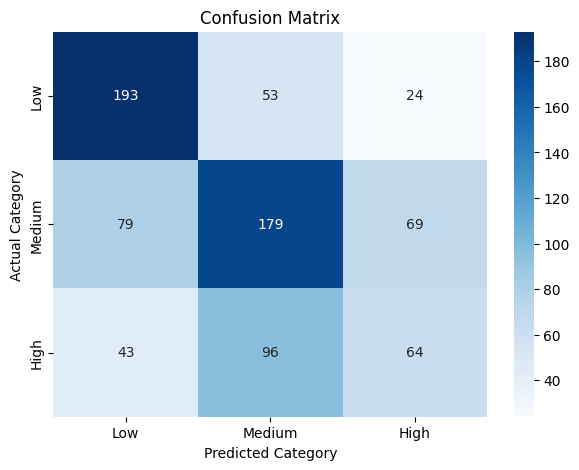

In [217]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix')

plt.show()

In [218]:
# Compare numerical features across premium categories

df_feat.groupby('insurance_premium_category')[
    ['age', 'bmi', 'income_lpa', 'city_tier']
].mean().round(2)

,age,bmi,income_lpa,city_tier
insurance_premium_category,,,,
High,45.53,0.0,28.28,1.99
Low,34.25,0.0,22.67,1.99
Medium,43.59,0.0,27.05,1.95


In [219]:
pd.crosstab(
    insurance['smoker'],
    insurance['insurance_premium_category'],
    normalize='index'
).round(3) * 100

insurance_premium_category,High,Low,Medium
smoker,,,
False,5.4,47.6,47.0
True,69.1,1.9,29.0


In [220]:
X = df_feat[
    [
        "bmi",
        "age_group",
        "lifestyle_risk",
        "city_tier",
        "income_lpa",
        "occupation"
    ]
]

In [221]:
X

,bmi,age_group,lifestyle_risk,city_tier,income_lpa,occupation
0,0.001840,Middle aged,low,2,29.90,Factory Worker
1,0.003189,Middle aged,low,2,19.22,Businessman
2,0.002746,Adult,low,3,36.95,Sales Manager
3,0.002782,Adult,low,3,14.75,Banker
4,0.001275,Adult,low,2,19.32,Marketing Manager
...,...,...,...,...,...,...
3995,0.002362,Adult,low,2,37.65,Insurance Agent
3996,0.002836,Adult,low,2,10.00,Data Analyst
3997,0.001726,Adult,low,2,28.63,Chef
3998,0.001727,Adult,low,3,12.01,Pharmacist


In [222]:
# Correct BMI calculation

df_feat["bmi"] = (
    df_feat["weight"] / (df_feat["height"] / 100) ** 2
)

# Check BMI values

df_feat[["weight", "height", "bmi"]].head(10)

,weight,height,bmi
0,57,176,18.401343
1,90,168,31.887755
2,87,178,27.458654
3,73,162,27.815882
4,47,192,12.749566
5,91,187,26.023049
6,72,184,21.266541
7,61,178,19.252620
8,63,184,18.608223
9,75,187,21.447568


In [223]:
def lifestyle_risk(row):
    if row["smoker"] and row["bmi"] > 30:
        return "high"
    elif row["smoker"] and row["bmi"] > 27:
        return "medium"
    else:
        return "low"


df_feat["lifestyle_risk"] = df_feat.apply(
    lifestyle_risk, axis=1
)

df_feat["lifestyle_risk"].value_counts()

,count
lifestyle_risk,
low,3580
high,258
medium,162


In [224]:
df_feat.groupby("insurance_premium_category")[
    ["age", "bmi", "income_lpa", "city_tier"]
].mean().round(2)

,age,bmi,income_lpa,city_tier
insurance_premium_category,,,,
High,45.53,26.40,28.28,1.99
Low,34.25,22.59,22.67,1.99
Medium,43.59,25.09,27.05,1.95


In [225]:
# Select original and corrected features

X = df_feat[
    [
        "age",
        "bmi",
        "income_lpa",
        "smoker",
        "city",
        "occupation"
    ]
]

y = df_feat["insurance_premium_category"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (4000, 6)
Target shape: (4000,)


In [226]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "smoker",
    "city",
    "occupation"
]

numeric_features = [
    "age",
    "bmi",
    "income_lpa"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

In [227]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['smoker', 'city',
                                                   'occupation']),
                                                 ('num', 'passthrough',
                                                  ['age', 'bmi',
                                                   'income_lpa'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [228]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

y_pred = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.895

Classification Report:
              precision    recall  f1-score   support

        High       0.89      0.90      0.89       202
         Low       0.93      0.91      0.92       267
      Medium       0.87      0.88      0.88       331

    accuracy                           0.90       800
   macro avg       0.90      0.90      0.90       800
weighted avg       0.90      0.90      0.90       800



In [229]:
train_pred = pipeline.predict(X_train)
test_pred = pipeline.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred))

Training Accuracy: 1.0
Testing Accuracy: 0.895


In [230]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("Cross Validation Scores:", cv_scores)

print("Mean CV Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.8890625 0.9125    0.8890625 0.8671875 0.9109375]
Mean CV Accuracy: 0.89375
Standard Deviation: 0.01671217744640116


In [231]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

pipeline_tuned = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    ))
])

pipeline_tuned.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['smoker', 'city',
                                                   'occupation']),
                                                 ('num', 'passthrough',
                                                  ['age', 'bmi',
                                                   'income_lpa'])])),
                ('classifier',
                 RandomForestClassifier(max_depth=10, min_samples_leaf=4,
                                        min_samples_split=10, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

In [232]:
from sklearn.metrics import accuracy_score, classification_report

train_pred = pipeline_tuned.predict(X_train)
test_pred = pipeline_tuned.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

Training Accuracy: 0.8834375
Testing Accuracy: 0.85375

Classification Report:
              precision    recall  f1-score   support

        High       0.84      0.84      0.84       202
         Low       0.91      0.87      0.89       267
      Medium       0.81      0.85      0.83       331

    accuracy                           0.85       800
   macro avg       0.86      0.85      0.85       800
weighted avg       0.86      0.85      0.85       800



In [233]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    "classifier__n_estimators": randint(100, 500),
    "classifier__max_depth": [None, 10, 15, 20, 25, 30],
    "classifier__min_samples_split": randint(2, 20),
    "classifier__min_samples_leaf": randint(1, 10),
    "classifier__max_features": ["sqrt", "log2"]
}

In [234]:
random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [235]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('cat',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               ['smoker',
                                                                                'city',
                                                                                'occupation']),
                                                                              ('num',
                                                                               'passthrough',
                                                                               ['age',
                                                                                'bmi',
                                                                                'income_lpa'])])),
                                             ('classifier',
                                              RandomForestClassifier(random_state=42))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'classifier__max_depth':...
                                        'classifier__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e6a1b887250>,
                                        'classifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e6a1867e030>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e6a1ba238a0>},
                   random_state=42, scoring='accuracy', verbose=1)

In [236]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Accuracy:")
print(random_search.best_score_)

Best Parameters:
{'classifier__max_depth': 25, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 8, 'classifier__n_estimators': 108}

Best CV Accuracy:
0.8956250000000001


In [237]:
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Test Accuracy: 0.89625

Classification Report:
              precision    recall  f1-score   support

        High       0.88      0.90      0.89       202
         Low       0.93      0.93      0.93       267
      Medium       0.88      0.87      0.88       331

    accuracy                           0.90       800
   macro avg       0.90      0.90      0.90       800
weighted avg       0.90      0.90      0.90       800



      Feature  Importance
3      smoker    0.347500
0         age    0.265250
1         bmi    0.253625
2  income_lpa    0.095625
4        city   -0.000250
5  occupation   -0.002875


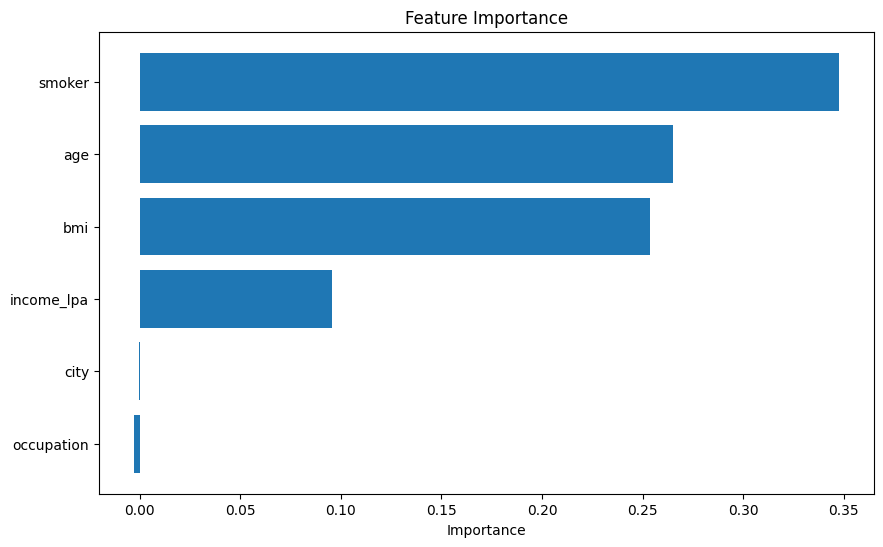

In [238]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.title("Feature Importance")

plt.gca().invert_yaxis()
plt.show()

In [239]:
# Select important features

selected_features = [
    "smoker",
    "age",
    "bmi",
    "income_lpa"
]

X_reduced = df_feat[selected_features]

y = df_feat["insurance_premium_category"]

# Split the data
from sklearn.model_selection import train_test_split

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create a new pipeline
reduced_pipeline = Pipeline(steps=[
    ("classifier", RandomForestClassifier(
        **{
            key.replace("classifier__", ""): value
            for key, value in random_search.best_params_.items()
        },
        random_state=42
    ))
])

# Train
reduced_pipeline.fit(X_train_r, y_train_r)

# Predict
pred_r = reduced_pipeline.predict(X_test_r)

print("Reduced Model Accuracy:",
      accuracy_score(y_test_r, pred_r))

print(classification_report(y_test_r, pred_r))

Reduced Model Accuracy: 0.92
              precision    recall  f1-score   support

        High       0.92      0.91      0.92       202
         Low       0.95      0.94      0.94       267
      Medium       0.90      0.91      0.90       331

    accuracy                           0.92       800
   macro avg       0.92      0.92      0.92       800
weighted avg       0.92      0.92      0.92       800



In [240]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    reduced_pipeline,
    X_reduced,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("CV Scores:", scores)

print("Mean CV Accuracy:", scores.mean())

print("Standard Deviation:", scores.std())

CV Scores: [0.9175  0.91    0.90625 0.92375 0.91875]
Mean CV Accuracy: 0.91525
Standard Deviation: 0.006294839156007063


In [241]:
df_feat.drop(columns=["lifestyle_risk"], inplace=True)

In [242]:
df_feat.columns

Index(['age', 'weight', 'height', 'income_lpa', 'smoker', 'city', 'occupation',
       'insurance_premium_category', 'bmi', 'age_group', 'city_tier'],
      dtype='object')

In [243]:
X = df_feat[["smoker", "age", "bmi", "income_lpa"]].copy()

y = df_feat["insurance_premium_category"].copy()

In [244]:
X.head()

,smoker,age,bmi,income_lpa
0,False,50,18.401343,29.90
1,False,56,31.887755,19.22
2,False,26,27.458654,36.95
3,False,34,27.815882,14.75
4,True,43,12.749566,19.32


In [245]:
X["smoker"] = X["smoker"].astype("category")

In [246]:
X.dtypes

,0
smoker,category
age,int64
bmi,float64
income_lpa,float64


In [247]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [248]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [249]:
print(dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
)))

{'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


In [250]:
!pip install -U xgboost

In [251]:
X = df_feat[["smoker", "age", "bmi", "income_lpa"]].copy()

y = df_feat["insurance_premium_category"].copy()

# Convert Boolean values into string categories
X["smoker"] = X["smoker"].astype(str).astype("category")

In [252]:
print(X.dtypes)
print(X["smoker"].cat.categories)

smoker        category
age              int64
bmi            float64
income_lpa     float64
dtype: object
Index(['False', 'True'], dtype='object')


In [253]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [254]:
print(X_train.dtypes)
print(X_train["smoker"].cat.categories)

smoker        category
age              int64
bmi            float64
income_lpa     float64
dtype: object
Index(['False', 'True'], dtype='object')


In [255]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [256]:
xgb_model.fit(X_train, y_train_encoded)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [257]:
y_pred_encoded = xgb_model.predict(X_test)

y_pred = label_encoder.inverse_transform(y_pred_encoded)

In [258]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

XGBoost Accuracy: 0.915

Classification Report:

              precision    recall  f1-score   support

        High       0.92      0.91      0.91       202
         Low       0.95      0.93      0.94       267
      Medium       0.89      0.91      0.90       331

    accuracy                           0.92       800
   macro avg       0.92      0.91      0.92       800
weighted avg       0.92      0.92      0.92       800


Confusion Matrix:

[[183   0  19]
 [  0 249  18]
 [ 17  14 300]]


In [259]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("XGBoost CV Scores:", xgb_cv_scores)
print("Mean CV Accuracy:", xgb_cv_scores.mean())
print("Standard Deviation:", xgb_cv_scores.std())

XGBoost CV Scores: [0.9125    0.915625  0.8984375 0.8875    0.9078125]
Mean CV Accuracy: 0.9043750000000002
Standard Deviation: 0.010241231005108731


In [261]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

categorical_features = ["smoker"]
numerical_features = ["age", "bmi", "income_lpa"]

preprocessor_rf = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

In [262]:
rf_params = {
    key.replace("classifier__", ""): value
    for key, value in random_search.best_params_.items()
}

rf_cv_pipeline = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        **rf_params,
        random_state=42,
        n_jobs=-1
    ))
])

In [266]:
X_rf = df_feat[["smoker", "age", "bmi", "income_lpa"]].copy()

y_rf = df_feat["insurance_premium_category"].copy()

In [268]:
from sklearn.model_selection import train_test_split

X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf,
    y_rf,
    test_size=0.2,
    random_state=42,
    stratify=y_rf
)

In [270]:
print(X_train_rf.shape)
print(X_test_rf.shape)
print(y_train_rf.shape)
print(y_test_rf.shape)

(3200, 4)
(800, 4)
(3200,)
(800,)


In [272]:
rf_cv_scores = cross_val_score(
    rf_cv_pipeline,
    X_train_rf,
    y_train_rf,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Mean CV Accuracy:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest CV Scores: [0.9234375 0.9171875 0.9046875 0.8984375 0.909375 ]
Mean CV Accuracy: 0.9106250000000001
Standard Deviation: 0.008860904299223656


In [273]:
import pickle

# Save the trained Random Forest pipeline
pickle_model_path = "insurance_model.pkl"

with open(pickle_model_path, "wb") as f:
    pickle.dump(rf_cv_pipeline, f)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!
